# Stage 4: forecasts and backtest

Finding 9 for **Wall Street in Charts**. The models live in `wallstreet/forecast.py` and run with `python models/run.py`.

> **Not financial advice.** These are illustrations from a simple model, not predictions.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import json

import pandas as pd
from IPython.display import SVG, display

from wallstreet import charts as C
from wallstreet import findings as F
from wallstreet import forecast as FC

pd.options.display.float_format = "{:,.2f}".format
MODELS = Path.cwd().parent / "models"

## Run settings

In [2]:
json.loads((MODELS / "settings.json").read_text())

{'seed': 20251231,
 'simulations': 10000,
 'block_quarters': 4,
 'driver_window': '1990Q1-2025Q4',
 'history': '2015Q1-2025Q4',
 'horizon': '2035Q4',
 'rate_long_run_mean': 2.027,
 'rate_pull_per_quarter': 0.036,
 'market_growth_per_year_history': 0.0931}

## The drivers

How the rate model behaves, and what the simulated market and rates look like (market: end-2025 = 100).

In [3]:
m = FC.fit_drivers(FC.load_drivers())
pd.Series(
    {
        "Rate long-run level (%)": m.rate_mean,
        "Share of the gap closed each quarter": m.rate_speed,
        "VIX persistence": m.vix_persist,
        "VIX reaction to a 1% market move": m.vix_market / 100,
    }
)

Rate long-run level (%)                 2.03
Share of the gap closed each quarter    0.04
VIX persistence                         0.82
VIX reaction to a 1% market move       -0.01
dtype: float64

In [4]:
F.driver_scenarios().loc[[2026, 2030, 2035]]

,market_bad,market_middling,market_good,rate_bad,rate_middling,rate_good
year,,,,,,
2026,89.44,106.85,120.32,2.47,3.63,4.96
2030,95.23,157.04,232.86,0.45,3.04,5.91
2035,122.34,244.92,447.22,0.23,2.65,5.85


## The firm models

R² says how much of the quarter-to-quarter variation each equation explains. Profit margins are mostly noise around an average (low R²), which is why the profit ranges are wide.

In [5]:
terms = pd.read_csv(MODELS / "model_terms.csv")
terms.groupby(["firm", "equation"])[["r2", "persistence", "quarters"]].first()

r2  persistence  quarters
firm           equation                                       
blackrock      AUM                 0.99         0.85        44
               profit margin       0.09         0.03        44
               revenue             0.97         0.18        44
goldman        net interest income 0.80         0.47        44
               other revenue       0.66         0.28        44
               profit margin       0.02         0.21        44
jpmorgan       net interest income 0.97         0.61        44
               other revenue       0.86         0.17        44
               profit margin       0.03         0.53        44
morgan_stanley net interest income 0.82         0.73        44
               other revenue       0.92         0.29        44
               profit margin       0.08         0.30        44
state_street   AUM                 0.99         0.66        44
               profit margin       0.04         0.08        44
               revenue             0.74         0.63        44

## Scenarios for profit ($bn)

In [6]:
rows = {}
for firm in F.LISTED:
    p = F.scenario_paths(firm, "net_income")
    rows[F.short_name(firm)] = {
        "2025": p.loc[2025, "middling"],
        **{f"2035 {s}": p.loc[2035, s] for s in F.SCENARIOS},
    }
pd.DataFrame(rows).T

,2025,2035 bad,2035 middling,2035 good
JPMorgan,57.05,49.47,74.95,109.45
Goldman,17.18,14.72,28.38,49.61
Morgan Stanley,16.86,17.63,29.95,49.01
BlackRock,5.55,9.61,14.29,20.73
State Street,2.94,2.64,3.24,3.85


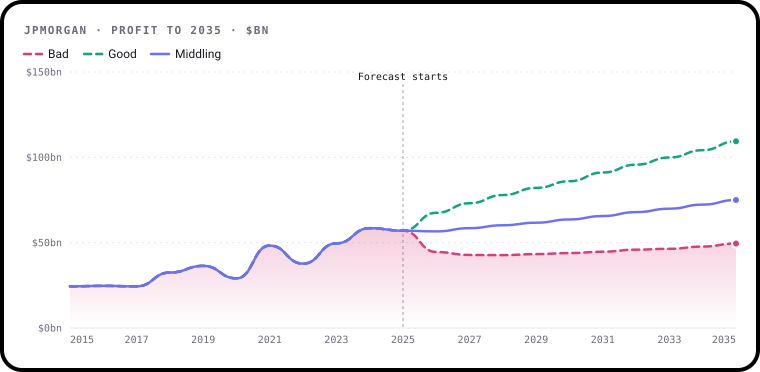

In [7]:
display(SVG(str(C.scenario_line("jpmorgan", "net_income", "light", width=C.WIDE))))

## Backtest

Trained on 2015 to 2020. `error` is the average yearly error with the real drivers fed in; `inside` is the share of years where reality fell inside the simulated bad-to-good range.

In [8]:
s = F.backtest_summary()[["error", "inside"]] * 100
s

error  inside
firm           metric                   
blackrock      aum         12.32   80.00
               net_income  13.59   80.00
               revenue     10.76   80.00
goldman        net_income  37.52   80.00
               revenue     12.35   80.00
jpmorgan       net_income   9.19   20.00
               revenue      4.91   80.00
morgan_stanley net_income  27.24   60.00
               revenue      7.99  100.00
state_street   aum          3.03  100.00
               net_income  16.65   80.00
               revenue     13.44  100.00

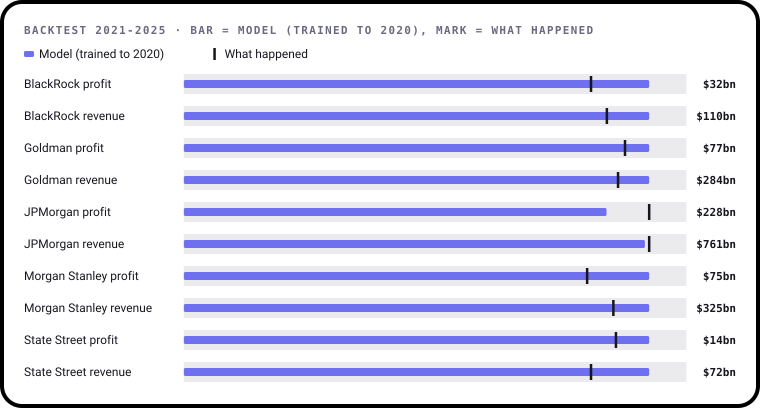

In [9]:
display(SVG(str(C.backtest_bullets("light"))))